# Gymnasium Env API

- This notebook explores the `gymnasium.Env` API, building up from the smallest
  working example on `CartPole-v1`
- The pedagogical arc:
  - `Env`, `reset()`, `step()`, and a full episode
  - `Space`: a first look, in depth in notebook 03
  - `render()`, `close()`, and the registry, in depth in notebook 02
  - A custom `Env`
  - Wrappers and vector envs: a first look, in depth in notebooks 04 and 05
- References:
  - API: https://gymnasium.farama.org/api/env
  - GitHub: https://github.com/Farama-Foundation/Gymnasium

In [1]:
!pip install -q "gymnasium[classic-control]==1.3.0" pygame-ce==2.5.8

import importlib.metadata

import gymnasium

print("gymnasium version: ", gymnasium.__version__)
print("pygame-ce version: ", importlib.metadata.version("pygame-ce"))

gymnasium version:  1.3.0


pygame-ce version:  2.5.8


In [2]:
%load_ext autoreload
%autoreload 2

import logging

import gymnasium as gym
import numpy as np
import pandas as pd
from gymnasium import spaces
from gymnasium.wrappers import RecordEpisodeStatistics, TimeLimit

In [3]:
import gymnasium_utils as utils
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /tmp/.ipython/profile_default/startup/00_shim.py


## Library Overview

- **What problem it solves**: RL algorithms need an environment (a world the
  agent acts in). Without a standard interface, every environment has a different
  API and agent code is not portable

- **Key abstraction**: `gymnasium.Env`: a single class every environment
  implements. It exposes four methods (`reset`, `step`, `render`, `close`) and
  two attributes (`observation_space`, `action_space`)

- **Mental model**: the agent calls `reset()` once, then loops calling `step()`
  until `terminated or truncated`

| Object | Description | Comments |
|--------|-------------|----------|
| `gym.make(id)` | Build a registered env | Adds standard wrappers such as `TimeLimit` |
| `env.reset(seed=...)` | Start an episode | Returns `(observation, info)` |
| `env.step(action)` | Advance one timestep | Returns `(observation, reward, terminated, truncated, info)` |
| `env.observation_space`, `env.action_space` | Describe valid data | `Space` objects |

- **Key classes**:
  - `gymnasium.Env`: base environment class
  - `gymnasium.spaces.*`: describe valid observations and actions
  - `gymnasium.Wrapper`: wrap an env to add behavior
  - `gymnasium.vector.VectorEnv`: run many envs in parallel

# Part 1: The `gymnasium.Env` base class

## Cell 1.1: Inspect `gymnasium.Env`

- **Mental model**: an object that holds the state of a world. You send it
  actions and it returns observations and rewards

- Every builtin and custom environment is a subclass of `gymnasium.Env`

In [4]:
# Inspect what Env exposes as a markdown list.
hintros.print_obj_info(gym.Env)

**Env**
- `close(self) -> 'None'`: After the user has finished using the environment, close contains the code necessary to "clean up" the environment.
- `get_wrapper_attr(self, name: 'str') -> 'Any'`: Gets the attribute `name` from the environment.
- `has_wrapper_attr(self, name: 'str') -> 'bool'`: Checks if the attribute `name` exists in the environment.
- `render(self) -> 'RenderFrame | list[RenderFrame] | None'`: Compute the render frames as specified by :attr:`render_mode` during the initialization of the environment.
- `reset(self, *, seed: 'int | None' = None, options: 'dict[str, Any] | None' = None) -> 'tuple[ObsType, dict[str, Any]]'`: Resets the environment to an initial internal state, returning an initial observation and info.
- `set_wrapper_attr(self, name: 'str', value: 'Any', *, force: 'bool' = True) -> 'bool'`: Sets the attribute `name` on the environment with `value`, see `Wrapper.set_wrapper_attr` for more info.
- `step(self, action: 'ActType') -> 'tuple[ObsType, SupportsFloat, bool, bool, dict[str, Any]]'`: Run one timestep of the environment's dynamics using the agent actions.

## Cell 1.2: Construct an `Env` with `gym.make()`

- `gym.make(id)` is the standard factory: it looks up a registered environment
  by string ID and returns a fully wrapped `Env`
- Use `render_mode=None` (default) to skip visual rendering (safe in notebooks)

In [5]:
# Create the simplest classic-control environment.
env = gym.make("CartPole-v1", render_mode=None)
# `reset(seed=...)` does not seed the action space, so seed it here.
env.action_space.seed(0)
print("type(env):", type(env))
print("env:", env)

type(env): <class 'gymnasium.wrappers.common.TimeLimit'>
env: <TimeLimit<OrderEnforcing<PassiveEnvChecker<CartPoleEnv<CartPole-v1>>>>>


## Cell 1.3: Inspect the env object

- Two key attributes describe the interface contract:
  - `observation_space`: what the env returns
  - `action_space`: what the env accepts

In [6]:
# Print type and content of env attributes.
print("observation_space type:", type(env.observation_space))
print("observation_space:", env.observation_space)

print("\naction_space type:", type(env.action_space))
print("action_space:", env.action_space)

print("\nspec:", env.spec)

print("\nunwrapped type:", type(env.unwrapped))
print("unwrapped:", env.unwrapped)

observation_space type: <class 'gymnasium.spaces.box.Box'>
observation_space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)

action_space type: <class 'gymnasium.spaces.discrete.Discrete'>
action_space: Discrete(2)

spec: EnvSpec(id='CartPole-v1', entry_point='gymnasium.envs.classic_control.cartpole:CartPoleEnv', reward_threshold=475.0, nondeterministic=False, max_episode_steps=500, order_enforce=True, disable_env_checker=False, kwargs={'render_mode': None}, namespace=None, name='CartPole', version=1, additional_wrappers=(), vector_entry_point='gymnasium.envs.classic_control.cartpole:CartPoleVectorEnv')

unwrapped type: <class 'gymnasium.envs.classic_control.cartpole.CartPoleEnv'>
unwrapped: <CartPoleEnv<CartPole-v1>>


# Part 2: The episode loop

## Cell 2.1: `reset()`: start an episode

- **Mental model**: puts the environment into an initial state and returns the
  first observation. Must be called before the first `step()`

- Signature:
  ```
  reset(*, seed=None, options=None) -> (observation, info)
  ```
  - `seed`: optional integer for reproducible randomness
  - `options`: optional dict of env-specific configuration
  - Returns `(observation, info)`: always a 2-tuple

In [7]:
# Reset and inspect the return values.
observation, info = env.reset(seed=42)
print("observation:", observation)
print("observation.shape:", observation.shape)
print("observation.dtype:", observation.dtype)
print("info:", info)

observation: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
observation.shape: (4,)
observation.dtype: float32
info: {}


In [8]:
# Show that reset is reproducible with the same seed.
obs1, _ = env.reset(seed=0)
obs2, _ = env.reset(seed=0)
print("Same seed -> same obs:", np.array_equal(obs1, obs2))

Same seed -> same obs: True


## Cell 2.2: `step()`: advance one timestep

- **Mental model**: applies one action, advances the world by one timestep, and
  returns what the agent sees next

- Signature:
  ```
  step(action) -> (observation, reward, terminated, truncated, info)
  ```
  - `terminated`: episode ended naturally (goal / failure)
  - `truncated`: episode cut off externally (time limit)
  - The distinction matters for value bootstrapping in RL algorithms

In [9]:
env.reset(seed=42)
# Take one random action and inspect all five return values.
action = env.action_space.sample()
obs, reward, terminated, truncated, info = env.step(action)
utils.print_step(obs, reward, terminated, truncated, info)

observation (4,): [ 0.02727336  0.18847767  0.03625453 -0.26141977]
reward: 1.0
terminated: False
truncated: False
info: {}


## Cell 2.3: Run a full episode

- The canonical episode loop: reset once, then step until done

In [10]:
# Seed the env and the action space, so that a rerun repeats the episode.
env.reset(seed=42)
env.action_space.seed(42)
total_reward = 0.0
step_count = 0
done = False
# Loop until the episode ends (either terminated or truncated).
while not done:
    # Sample a random action from the action space.
    action = env.action_space.sample()
    # Advance the environment by one timestep.
    _obs, reward, terminated, truncated, _info = env.step(action)
    total_reward += reward
    step_count += 1
    # An episode ends when terminated (goal/failure) or truncated (time limit).
    done = terminated or truncated
print(f"Steps: {step_count}  Total reward: {total_reward}")

Steps: 30  Total reward: 30.0


# Part 3: Spaces: describing valid data

- **Mental model**:
    - A `Space` is a typed contract
    - It knows the shape, dtype, and bounds of valid data
    - It can sample random valid values and check membership

- Every env has exactly two spaces:
  - `env.observation_space`: type of observations returned by `step`/`reset`
  - `env.action_space`: type of actions accepted by `step`

## Cell 3.1: `Discrete(n)`: integers 0...n-1

In [11]:
# `Discrete(n)` represents a set of n integer values 0, 1, ..., n-1.
# It is used for action spaces with a finite number of discrete choices
# (e.g., move left/right in CartPole has n=2).
d = spaces.Discrete(3)
# Seed the space so that reruns print the same samples.
d.seed(0)
print("type:", type(d))
print("n:", d.n)
print("dtype:", d.dtype)

type: <class 'gymnasium.spaces.discrete.Discrete'>
n: 3
dtype: int64


In [12]:
# Sample several times to see the range.
samples = [int(d.sample()) for _ in range(10)]
print("samples:", samples)

samples: [2, 1, 1, 0, 0, 0, 0, 0, 0, 2]


In [13]:
# Membership check.
print("2 in d:", d.contains(2))
print("5 in d:", d.contains(5))

2 in d: True
5 in d: False


## Cell 3.2: `Box(low, high, shape)`: continuous tensor

In [14]:
# `Box(low, high, shape)` represents a continuous tensor where each element is
# bounded in [low, high]. It is used for observation spaces with continuous
# values (e.g., position, velocity in CartPole has shape (4,) with bounds).
b = spaces.Box(low=-1.0, high=1.0, shape=(3,), dtype=np.float32)
b.seed(0)

print("type:", type(b))
print("low:", b.low)
print("high:", b.high)
print("shape:", b.shape)
print("dtype:", b.dtype)
print("sample:", b.sample())
print(
    "contains [0.5, -0.5, 0.0]:",
    b.contains(np.array([0.5, -0.5, 0.0], dtype=np.float32)),
)
print(
    "contains [2.0, 0.0, 0.0]:",
    b.contains(np.array([2.0, 0.0, 0.0], dtype=np.float32)),
)

type: <class 'gymnasium.spaces.box.Box'>
low: [-1. -1. -1.]
high: [1. 1. 1.]
shape: (3,)
dtype: float32
sample: [ 0.27392337 -0.46042657 -0.918053  ]
contains [0.5, -0.5, 0.0]: True
contains [2.0, 0.0, 0.0]: False


## Cell 3.3: Space comparison: CartPole vs MountainCar

In [15]:
cart = gym.make("CartPole-v1")
mountain = gym.make("MountainCar-v0")
# Compare observation and action spaces of two classic-control envs.
for name, e in [("CartPole-v1", cart), ("MountainCar-v0", mountain)]:
    print(f"{name}:")
    print(f"  obs_space: {e.observation_space}")
    print(f"  obs_shape: {e.observation_space.shape}")
    print(f"  act_space: {e.action_space}")
    print()
cart.close()
mountain.close()

CartPole-v1:
  obs_space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
  obs_shape: (4,)
  act_space: Discrete(2)

MountainCar-v0:
  obs_space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
  obs_shape: (2,)
  act_space: Discrete(3)



## Cell 3.4: Other space types

In [16]:
# MultiDiscrete: vector of independent discrete dims.
md = spaces.MultiDiscrete([3, 4, 2])
md.seed(0)
print("MultiDiscrete sample:", md.sample())

MultiDiscrete sample: [1 1 0]


In [17]:
# MultiBinary: vector of n binary flags.
mb = spaces.MultiBinary(5)
mb.seed(0)
print("MultiBinary sample:", mb.sample())

MultiBinary sample: [0 1 1 1 1]


In [18]:
# Dict: named collection of spaces.
dict_space = spaces.Dict(
    {
        "pos": spaces.Box(low=0.0, high=1.0, shape=(2,), dtype=np.float32),
        "speed": spaces.Discrete(5),
    }
)
dict_space.seed(0)
print("Dict sample:", dict_space.sample())

Dict sample: {'pos': array([0.6822636 , 0.18933342], dtype=float32), 'speed': np.int64(2)}


In [19]:
# Tuple: ordered collection of spaces.
tup = spaces.Tuple((spaces.Discrete(3), spaces.Box(0.0, 1.0, shape=(2,))))
tup.seed(0)
print("Tuple sample:", tup.sample())

Tuple sample: (np.int64(1), array([0.82711583, 0.27574444], dtype=float32))


# Part 4: Rendering and the registry

## Cell 4.1: `render()` and `close()`

- `render()`: returns a visual representation of the current state
  - `render_mode="rgb_array"` -> numpy uint8 array `(H, W, 3)`
  - `render_mode="human"` -> opens a display window
- `close()`: releases resources (windows, file handles, networking)

In [20]:
# Use rgb_array mode to capture a frame without opening a window.
# Rendering needs the `classic-control` extra, installed by the first code cell.
env_rgb = gym.make("CartPole-v1", render_mode="rgb_array")
env_rgb.reset(seed=0)
frame = env_rgb.render()
print("frame type:", type(frame))
print("frame shape:", frame.shape)
print("frame dtype:", frame.dtype)
env_rgb.close()

frame type: <class 'numpy.ndarray'>
frame shape: (400, 600, 3)
frame dtype: uint8


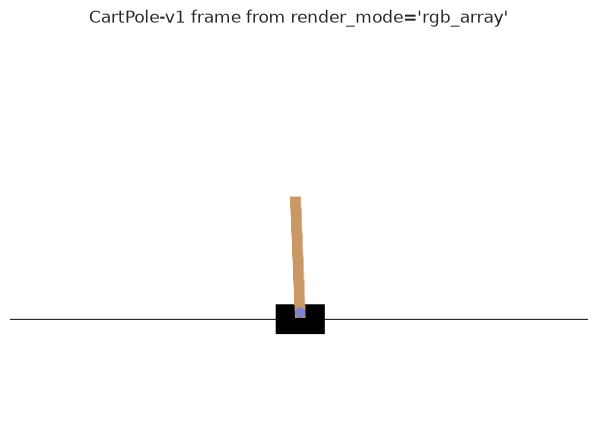

In [21]:
# Show the frame: this is what `render_mode="rgb_array"` returns.
utils.plot_frame(frame, "CartPole-v1 frame from render_mode='rgb_array'")

In [22]:
# Always close when finished.
env.close()
print("env closed")

env closed


## Cell 4.2: `gym.make()`: the environment registry

- `gym.make(id, **kwargs)` looks up the ID in a global registry and wraps the
  result in standard wrappers (e.g. `TimeLimit`)
- `gym.envs.registry` is a dict of `EnvSpec` objects

In [23]:
# Show a sample of registered environments.
all_ids = sorted(gym.envs.registry.keys())
print(f"Total registered environments: {len(all_ids)}")
sample_ids = all_ids[:10]
display(pd.DataFrame({"id": sample_ids}))

Total registered environments: 63


,id
0,Acrobot-v1
1,Ant-v2
2,Ant-v3
3,Ant-v4
4,Ant-v5
5,BipedalWalker-v3
6,BipedalWalkerHardcore-v3
7,Blackjack-v1
8,CarRacing-v3
9,CartPole-v0


In [24]:
# Inspect an EnvSpec.
spec = gym.spec("CartPole-v1")
data = {
    "field": ["id", "entry_point", "max_episode_steps", "reward_threshold"],
    "value": [
        spec.id,
        spec.entry_point,
        spec.max_episode_steps,
        spec.reward_threshold,
    ],
}
display(pd.DataFrame(data))

,field,value
0,id,CartPole-v1
1,entry_point,gymnasium.envs.classic_control.cartpole:CartPo...
2,max_episode_steps,500
3,reward_threshold,475.0


# Part 5: Composition

## Cell 5.1: Build a custom `Env`

- Subclass `gym.Env`, declare the two spaces, and implement `reset` and `step`
- Minimum required: `__init__`, `reset`, `step`
- `action_space` / `observation_space` must be set in `__init__`

In [25]:
class OneDGridEnv(gym.Env):
    """
    Walk a 1-D grid to reach position (size-1).
    """

    def __init__(self, size: int = 5) -> None:
        super().__init__()
        # Grid length and starting position (leftmost cell).
        self._size = size
        self._pos = 0
        # Observation: current integer position (0 to size-1).
        self.observation_space = spaces.Discrete(size)
        # Actions: 0 = left, 1 = right.
        self.action_space = spaces.Discrete(2)

    def reset(self, *, seed=None, options=None):
        # Reset the RNG and place the agent at the leftmost cell.
        super().reset(seed=seed)
        self._pos = 0
        return self._pos, {}

    def step(self, action):
        # Move right (action=1) or left (action=0), clamped to grid bounds.
        self._pos += 1 if action == 1 else -1
        self._pos = int(np.clip(self._pos, 0, self._size - 1))
        # Episode terminates when the agent reaches the rightmost cell.
        terminated = self._pos == self._size - 1
        # Reward is 1 only on reaching the goal, 0 otherwise.
        reward = 1.0 if terminated else 0.0
        return self._pos, reward, terminated, False, {}

In [26]:
# Verify the custom env behaves like any other Gym env.
custom_env = OneDGridEnv(size=5)
# Walk right until done.
steps, _ = utils.run_episode(custom_env, seed=7, policy=lambda _obs: 1)
for idx, step in enumerate(steps):
    utils.print_step(*step, label=f"Step {idx}", compact=True)

Step 0 obs=1 rew=0.0 term=False trunc=False info={}
Step 1 obs=2 rew=0.0 term=False trunc=False info={}
Step 2 obs=3 rew=0.0 term=False trunc=False info={}
Step 3 obs=4 rew=1.0 term=True trunc=False info={}


## Cell 5.2: Register and use a custom env with `gym.make()`

In [27]:
# Register the custom env so it can be created via gym.make().
gym.register(id="OneDGrid-v0", entry_point=OneDGridEnv, max_episode_steps=20)
# Create the registered env with a custom size (overriding the default).
env2 = gym.make("OneDGrid-v0", size=4)
# Reset returns the starting position (0 for leftmost cell).
obs, _ = env2.reset(seed=0)
print("obs after reset:", obs)
# Step right: action=1 moves one cell to the right.
obs, reward, terminated, truncated, info = env2.step(1)
print("obs after step right:", obs, "reward:", reward)
# Clean up the env.
env2.close()

obs after reset: 0
obs after step right: 1 reward: 0.0


## Cell 5.3: Wrappers

- **Mental model**:
    - A `Wrapper` wraps an `Env` and intercepts its calls
    - The wrapped object is still an `Env` and can be wrapped again
    - Wrappers avoid modifying environment code while adding behavior

In [28]:
base_env = gym.make("CartPole-v1")
# Stack two wrappers.
env_w = TimeLimit(base_env, max_episode_steps=50)
env_w = RecordEpisodeStatistics(env_w)
print("type of wrapped env:", type(env_w))
print("is still Env?", isinstance(env_w, gym.Env))
# unwrapped reaches through all wrapper layers.
print("unwrapped type:", type(env_w.unwrapped))

type of wrapped env: <class 'gymnasium.wrappers.common.RecordEpisodeStatistics'>
is still Env? True
unwrapped type: <class 'gymnasium.envs.classic_control.cartpole.CartPoleEnv'>


In [29]:
# Run an episode and inspect the statistics injected into `info`.
steps, _ = utils.run_episode(env_w, seed=0)
for step in steps:
    # Use compact=True to print all five values on a single line.
    utils.print_step(*step, compact=True)
# RecordEpisodeStatistics adds 'episode' key at episode end.
print("episode stats:", steps[-1].info["episode"])
env_w.close()

obs=(4,): [ 0.01323574  0.17272775 -0.04686959 -0.3551522 ] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.0166903   0.3684837  -0.05397264 -0.66223824] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.02405997  0.5643134  -0.0672174  -0.97141534] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.03534624  0.3701548  -0.08664571 -0.70058215] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.04274933  0.17633402 -0.10065735 -0.43638363] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.04627601 -0.01722973 -0.10938502 -0.17705095] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.04593142 -0.21063012 -0.11292604  0.07922072] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.04171882 -0.40396732 -0.11134163  0.33424965] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.03363947 -0.5973431  -0.10465664  0.5898503 ] rew=1.0 term=False trunc=False info={}
obs=(4,): [ 0.02169261 -0.40092343 -0.09285963  0.26612002] rew=1.0 term=False trunc=False info={}
obs=(4,): 

## Cell 5.4: Vectorized environments

- **Mental model**: a `VectorEnv` steps a batch of envs simultaneously.
  Observations, rewards, and flags become arrays with a leading batch dimension
- Auto-resets sub-envs when their episodes end, so the batch keeps stepping

In [30]:
# Run 3 CartPole envs in parallel.
vec_env = gym.make_vec("CartPole-v1", num_envs=3, vectorization_mode="sync")
vec_env.action_space.seed(0)
print("type:", type(vec_env))
obs_batch, info_batch = vec_env.reset(seed=0)
print("obs_batch shape:", obs_batch.shape)  # (3, 4)
# Step all 3 envs simultaneously.
actions = vec_env.action_space.sample()
print("actions batch:", actions)
obs_batch, rewards, terminations, truncations, info_batch = vec_env.step(actions)
data = {
    "field": ["obs_batch.shape", "rewards", "terminations", "truncations"],
    "value": [
        str(obs_batch.shape),
        str(rewards),
        str(terminations),
        str(truncations),
    ],
}
display(pd.DataFrame(data))
vec_env.close()

type: <class 'gymnasium.vector.sync_vector_env.SyncVectorEnv'>
obs_batch shape: (3, 4)
actions batch: [1 0 0]


,field,value
0,obs_batch.shape,"(3, 4)"
1,rewards,[1. 1. 1.]
2,terminations,[False False False]
3,truncations,[False False False]


# Part 6: Interactive exploration

## Cell 6.1: Explore any env's interface

In [31]:
# Explore any env's interface.
env6 = gym.make("MountainCar-v0")
env6.action_space.seed(0)
hintros.print_obj_info(type(env6))

**TimeLimit**
- `class_name() -> 'str'`: Returns the class name of the wrapper.
- `close(self) -> 'None'`: Closes the wrapper and :attr:`env`.
- `get_wrapper_attr(self, name: 'str') -> 'Any'`: Gets an attribute from the wrapper and lower environments if `name` doesn't exist in this object.
- `has_wrapper_attr(self, name: 'str') -> 'bool'`: Checks if the given attribute is within the wrapper or its environment.
- `render(self) -> 'RenderFrame | list[RenderFrame] | None'`: Uses the :meth:`render` of the :attr:`env` that can be overwritten to change the returned data.
- `reset(self, *, seed: 'int | None' = None, options: 'dict[str, Any] | None' = None) -> 'tuple[ObsType, dict[str, Any]]'`: Resets the environment with :param:`**kwargs` and sets the number of steps elapsed to zero.
- `set_wrapper_attr(self, name: 'str', value: 'Any', *, force: 'bool' = True) -> 'bool'`: Sets an attribute on this wrapper or lower environment if `name` is already defined.
- `step(self, action: 'ActType') -> 'tuple[ObsType, SupportsFloat, bool, bool, dict[str, Any]]'`: Steps through the environment and if the number of steps elapsed exceeds ``max_episode_steps`` then truncate.
- `wrapper_spec(**kwargs: 'Any') -> 'WrapperSpec'`: Generates a `WrapperSpec` for the wrappers.

In [32]:
# What does reset return?
obs, info = env6.reset(seed=0)
print("obs:", obs, "  info:", info)

obs: [-0.47260767  0.        ]   info: {}


In [33]:
# What does a random step look like?
obs, reward, terminated, truncated, info = env6.step(env6.action_space.sample())
print("obs:", obs, "reward:", reward, "terminated:", terminated)

obs: [-0.47198862  0.00061906] reward: -1.0 terminated: False


In [34]:
# What is the observation space bound?
print("obs low:", env6.observation_space.low)
print("obs high:", env6.observation_space.high)
env6.close()

obs low: [-1.2  -0.07]
obs high: [0.6  0.07]


## Summary: The Mental Model

- `gymnasium.Env` is the single interface for all RL environments: call
  `reset()` to start an episode and `step(action)` in a loop to advance it
- Two `Space` objects (`observation_space`, `action_space`) encode the contract:
  they define valid data types, shapes, and bounds and can sample random valid
  values
- Wrappers extend behavior by composition without modifying environment code,
  and `VectorEnv` parallelizes a batch of envs under the same interface
- A custom environment is just a subclass of `gym.Env` that declares the two
  spaces and implements `reset` and `step`